# Function 1: Black-box optimisation

This notebook documents 13 rounds of model fitting, candidate selection and evaluated outputs for Function 1. Alternative approaches are retained where they informed the weekly decisions.

**Main result:** Late directional modelling improved the best output to 6.756159 × 10⁻⁶ in Week 13.

**Usage:** Run the setup and then the weekly sections in order. The initial datasets are in this folder; the full query history is in [`weekly_submissions.csv`](../submissions/weekly_submissions.csv). Some early searches generate large candidate grids and may require substantial memory.

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.optimize import differential_evolution, minimize
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, RBF


def resolve_initial_path(filename: str) -> Path:
    """Find the initial dataset for Function 1."""
    for folder in (Path.cwd(), Path.cwd() / "function_1"):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"{filename} not found. Place it in the function_1/ folder."
    )

## Reusable routines

The helper functions below handle standard GP fitting, UCB scoring and recording evaluated queries. The model settings and experiments remain visible within each week.

In [2]:
def fit_gp_model(X, y, **settings):
    """Fit a GP using the explicit kernel and settings chosen for a given week."""
    gp = GaussianProcessRegressor(**settings)
    gp.fit(X, y)
    return gp


def ucb_score(mean, std, beta):
    """Upper Confidence Bound: predictive mean plus weighted uncertainty."""
    return mean + beta * std


def add_evaluation(X, y, x_observed, y_observed):
    """Add one completed black-box evaluation to the training history."""
    x_row = np.asarray(x_observed, dtype=float).reshape(1, -1)
    y_value = np.asarray(y_observed, dtype=float).reshape(1)
    if x_row.shape[1] != X.shape[1]:
        raise ValueError("The evaluated input has the wrong number of dimensions.")
    return np.vstack([X, x_row]), np.concatenate([y, y_value])


### GP surface visualisations

In [3]:
def plot_2d_surface(
    X1_grid,
    X2_grid,
    values,
    X_obs,
    candidate,
    *,
    title,
    colorbar_label,
    candidate_label="Next UCB query",
):
    """Plot one two-dimensional surface and highlight the observations and query."""
    surface = np.asarray(values).reshape(X1_grid.shape)
    fig, ax = plt.subplots(figsize=(10, 6))

    contours = ax.contourf(X1_grid, X2_grid, surface, levels=20)
    fig.colorbar(contours, ax=ax, label=colorbar_label)

    ax.scatter(
        X_obs[:, 0], X_obs[:, 1],
        marker="x", s=100, label="Existing observations"
    )
    ax.scatter(
        candidate[0], candidate[1],
        marker="*", s=200, label=candidate_label
    )

    ax.set(xlabel="X1", ylabel="X2", title=title)
    ax.legend()
    plt.show()


def plot_gp_diagnostics_2d(
    X1_grid, X2_grid, post_mean, post_std, ucb, X_obs, candidate
):
    """Plot the GP posterior mean, uncertainty and UCB acquisition surface."""
    diagnostics = (
        (post_mean, "Gaussian Process Posterior Mean", "GP predicted mean", "Next UCB query"),
        (post_std, "Gaussian Process Uncertainty", "GP standard deviation", "Next UCB query"),
        (ucb, "UCB Acquisition Function", "UCB", "Highest UCB"),
    )
    for values, title, colorbar_label, candidate_label in diagnostics:
        plot_2d_surface(
            X1_grid,
            X2_grid,
            values,
            X_obs,
            candidate,
            title=title,
            colorbar_label=colorbar_label,
            candidate_label=candidate_label,
        )


## Starting data

In [4]:
X = np.load(resolve_initial_path("initial_inputs.npy"))
y = np.load(resolve_initial_path("initial_outputs.npy"))

## Week 1

Next input combination suggested by UCB:
[0.83683684 0.76976977]

Predicted mean:
0.0011117151317298526

Predicted standard deviation:
0.0008559110449838161

UCB:
0.002789300779898132


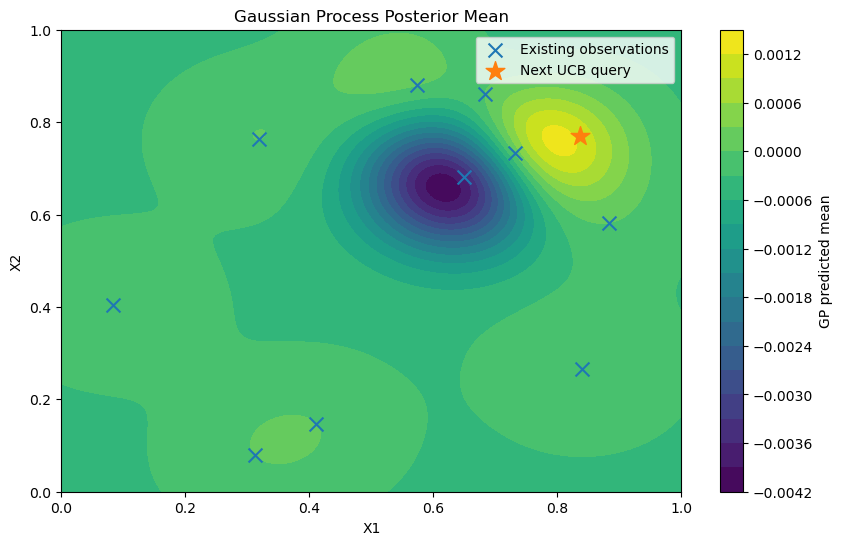

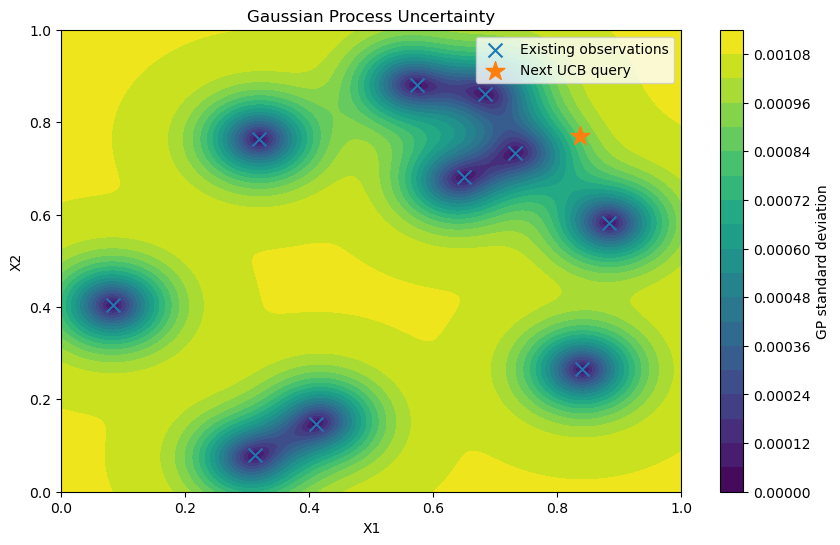

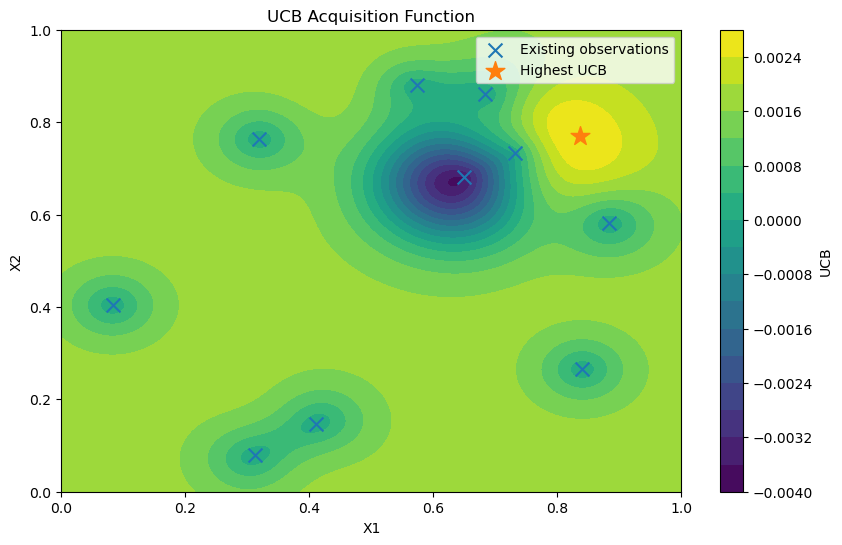

In [5]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = 0.1

# UCB exploration parameter
beta = 1.96
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds="fixed"
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True
)
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 1000)
x2_values = np.linspace(0, 1, 1000)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Evaluated query

**Input:** `(0.836837, 0.769770)`  
**Output:** `-7.263143484488904e-45`

In [6]:
X_week1 = np.array([0.836837, 0.76977])
y_week1 = np.array([-7.263143484488904e-45])
X_new, y_new = add_evaluation(X, y, X_week1, y_week1)

## Week 2

In [7]:
X = X_new
y = y_new

### Increase β to favour exploration

In [8]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = 0.1

beta = 3

### Allow the kernel length scale to vary

In [9]:
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds=(0.1, 1.0)
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Initial kernel:")
print(kernel)

print("\nOptimised kernel:")
print(model.kernel_)

Initial kernel:
RBF(length_scale=0.1)

Optimised kernel:
RBF(length_scale=0.1)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 0.1. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


### Increase candidate-grid resolution

In [10]:
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 5001)
x2_values = np.linspace(0, 1, 5001)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

Next input combination suggested by UCB:
[0.4084 0.9602]

Predicted mean:
-0.00014796181670496183

Predicted standard deviation:
0.0010086903472456565

UCB:
0.002878109225032008


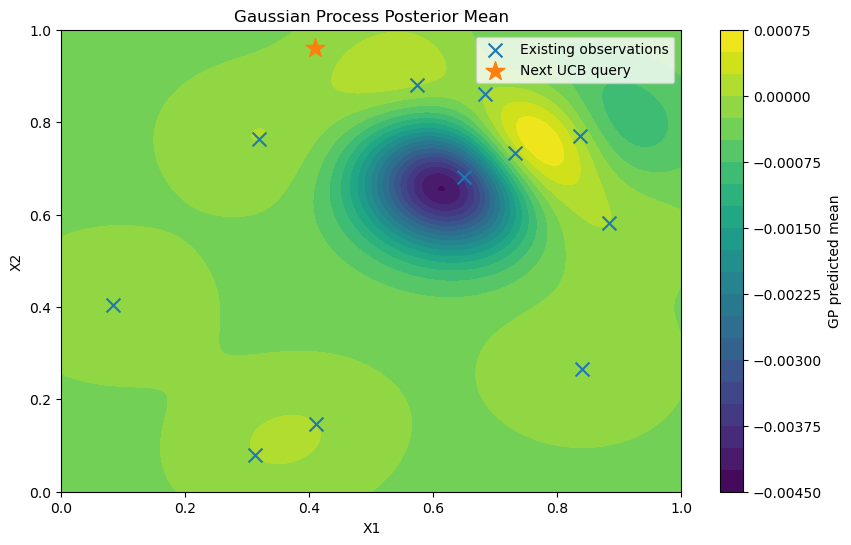

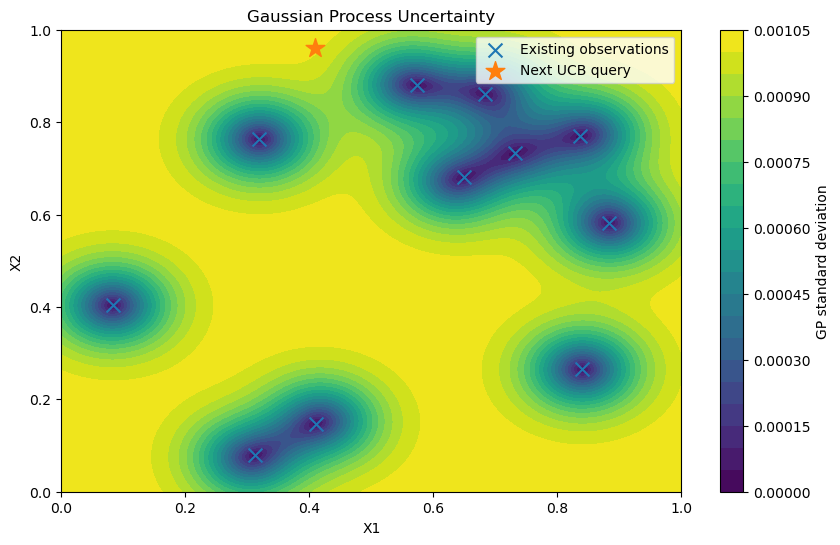

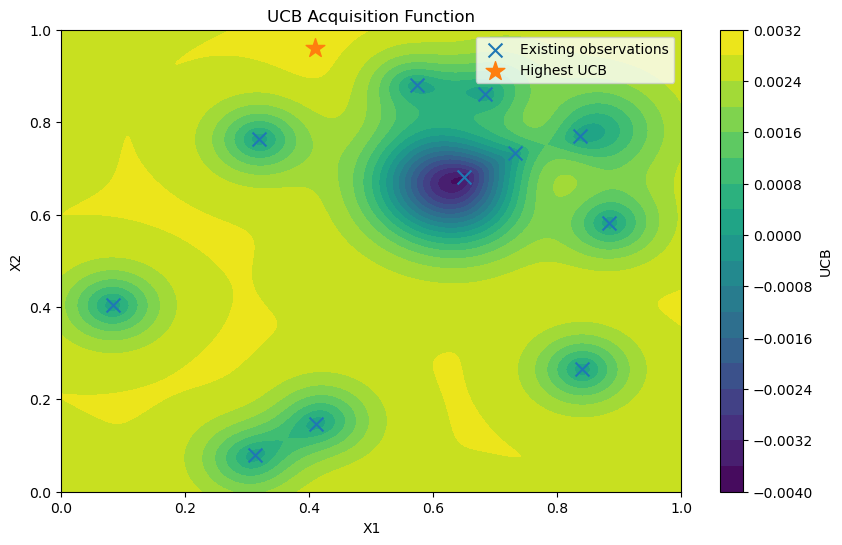

In [11]:
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Evaluated query

**Input:** `(0.408400, 0.960200)`  
**Output:** `-9.685082535584837e-111`

In [12]:
X_week2 = np.array([0.4084, 0.9602])
y_week2 = np.array([-9.685082535584837e-111])
X_new, y_new = add_evaluation(X, y, X_week2, y_week2)

## Week 3

In [13]:
X = X_new
y = y_new

### Option 1: β = 3 with lower length-scale bound 0.05

In [14]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = 0.1

beta = 3

In [15]:
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds=(0.05, 1.0)
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Initial kernel:")
print(kernel)

print("\nOptimised kernel:")
print(model.kernel_)

Initial kernel:
RBF(length_scale=0.1)

Optimised kernel:
RBF(length_scale=0.05)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 0.05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [16]:
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 5001)
x2_values = np.linspace(0, 1, 5001)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

Next input combination suggested by UCB:
[0.8054 0.6764]

Predicted mean:
-0.00013639608327449155

Predicted standard deviation:
0.0009714187634627601

UCB:
0.002777860207113789


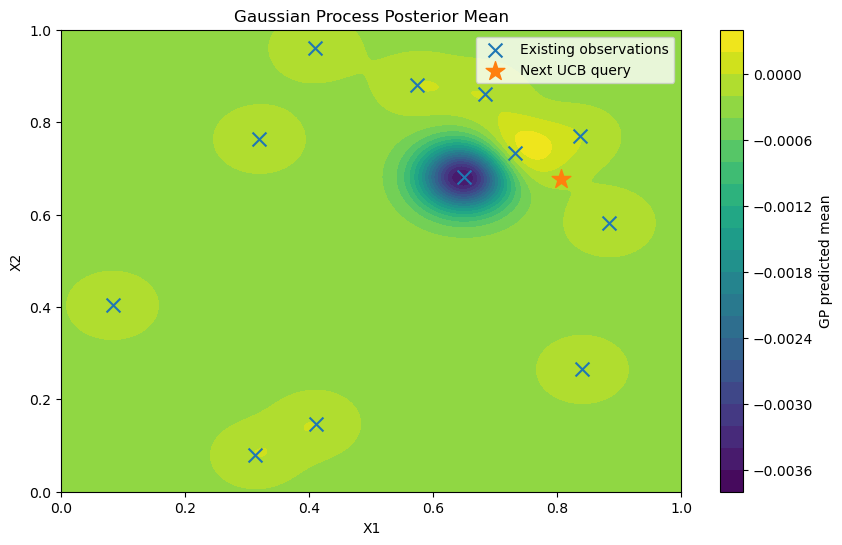

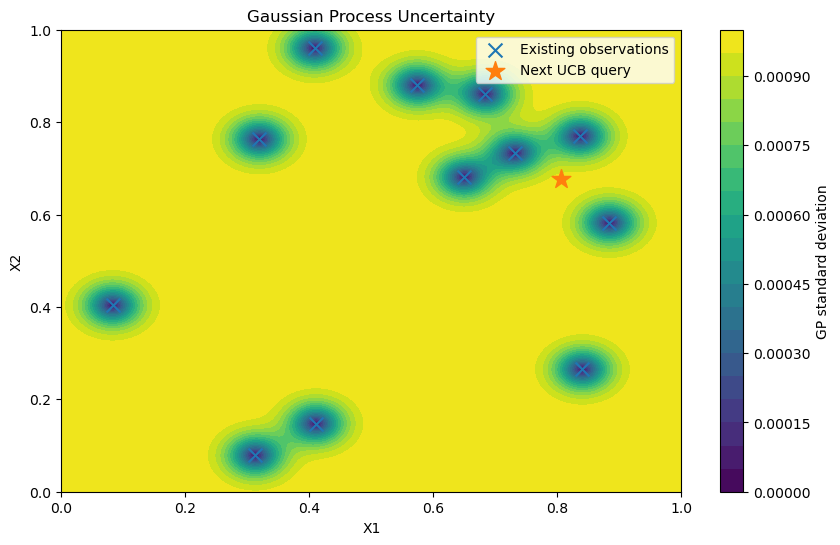

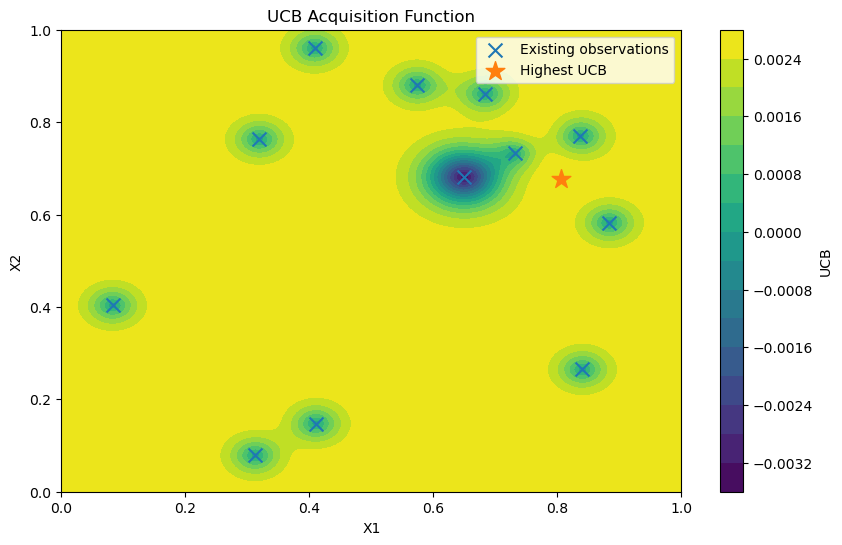

In [17]:
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Option 2: Maximum-distance candidate · selected

In [18]:
distances = cdist(X_grid, X)

nearest_distance = distances.min(axis=1)

farthest_index = np.argmax(nearest_distance)

most_unexplored_X = X_grid[farthest_index]

print(most_unexplored_X)
print(nearest_distance[farthest_index])

[0. 1.]
0.39775256435676853


### Evaluated query

**Input:** `(0.000000, 1.000000)`  
**Output:** `0.0`

In [19]:
X_week3 = np.array([0., 1.])
y_week3 = np.array([0.0])
X_new, y_new = add_evaluation(X, y, X_week3, y_week3)

## Week 4

In [20]:
X = X_new
y = y_new

### GP mean-only exploitation (β = 0)

In [21]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = 0.1

beta = 0

In [22]:
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds=(0.05, 1.0)
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Initial kernel:")
print(kernel)

print("\nOptimised kernel:")
print(model.kernel_)

Initial kernel:
RBF(length_scale=0.1)

Optimised kernel:
RBF(length_scale=0.05)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 0.05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [23]:
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 5001)
x2_values = np.linspace(0, 1, 5001)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

Next input combination suggested by UCB:
[0.7588 0.7494]

Predicted mean:
0.00031001851421858054

Predicted standard deviation:
0.000516977692035465

UCB:
0.00031001851421858054


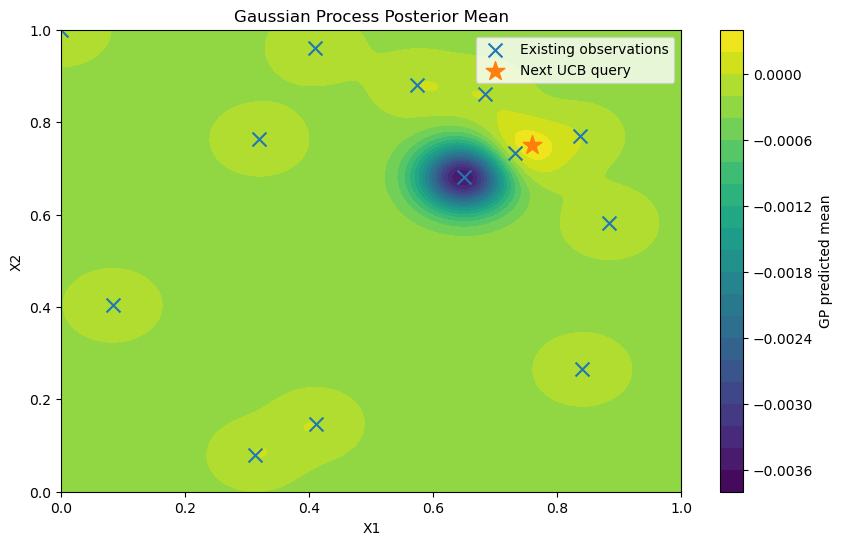

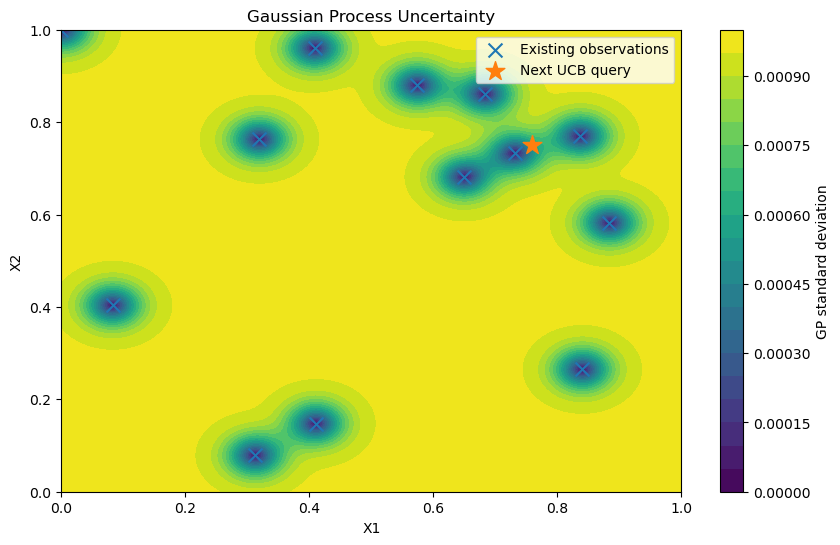

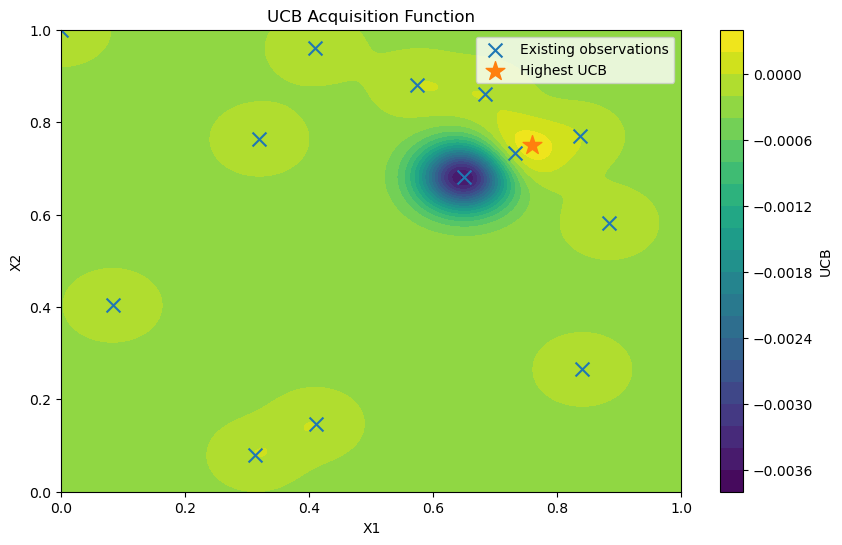

In [24]:
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Evaluated query

**Input:** `(0.758800, 0.749400)`  
**Output:** `1.3336189422117455e-23`

In [25]:
X_week4 = np.array([0.7588, 0.7494])
y_week4 = np.array([1.3336189422117455e-23])
X_new, y_new = add_evaluation(X, y, X_week4, y_week4)

## Week 5

In [26]:
X = X_new
y = y_new

In [27]:
# Build a tree of existing observations
tree = cKDTree(X)

# Maximise the distance to the nearest observation
def exploration_objective(x):
    nearest_distance, _ = tree.query(x)
    return -nearest_distance

# Restrict search to the interior of the domain
bounds = [(0.05, 0.95), (0.05, 0.95)]

result = differential_evolution(
    exploration_objective,
    bounds=bounds,
    seed=42,
    popsize=25,
    maxiter=600,
    tol=1e-9,
    polish=True
)

next_X = np.round(result.x, 6)

nearest_distance, _ = tree.query(next_X)

print("Recommended Week 5 input:", next_X)
print("Distance to nearest observation:", nearest_distance)

Recommended Week 5 input: [0.421062 0.463562]
Distance to nearest observation: 0.316185324270397


### Evaluated query

**Input:** `(0.421062, 0.463562)`  
**Output:** `-0.006627379464825304`

In [28]:
X_week5 = np.array([0.421062, 0.463562])
y_week5 = np.array([-0.006627379464825304])
X_new, y_new = add_evaluation(X, y, X_week5, y_week5)

## Week 6

In [29]:
X = X_new
y = y_new

### Option 1: GP mean-only exploitation (β = 0) · alternative

In [30]:
# GP configuration
noise_assumption = 1e-10
rbf_lengthscale = 0.1

beta = 0

In [31]:
# Configure the Gaussian Process
kernel = RBF(
    length_scale=rbf_lengthscale,
    length_scale_bounds=(0.05, 1.0)
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=noise_assumption,
    normalize_y=True,
    n_restarts_optimizer=10,
    random_state=42
)

print("Initial kernel:")
print(kernel)

print("\nOptimised kernel:")
print(model.kernel_)

Initial kernel:
RBF(length_scale=0.1)

Optimised kernel:
RBF(length_scale=0.0596)


In [32]:
# Generate candidate inputs
# Define the search range for each input variable

x1_values = np.linspace(0, 1, 5001)
x2_values = np.linspace(0, 1, 5001)

# Generate every combination of x1 and x2
X1_grid, X2_grid = np.meshgrid(
    x1_values,
    x2_values
)

X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

Next input combination suggested by UCB:
[0.742  0.7422]

Predicted mean:
7.939609331569081e-05

Predicted standard deviation:
9.366735919631864e-05

UCB:
7.939609331569081e-05


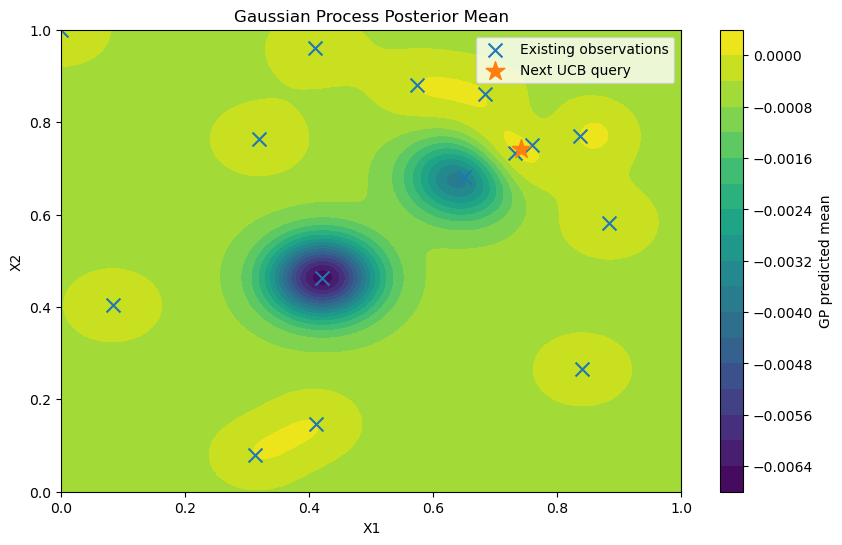

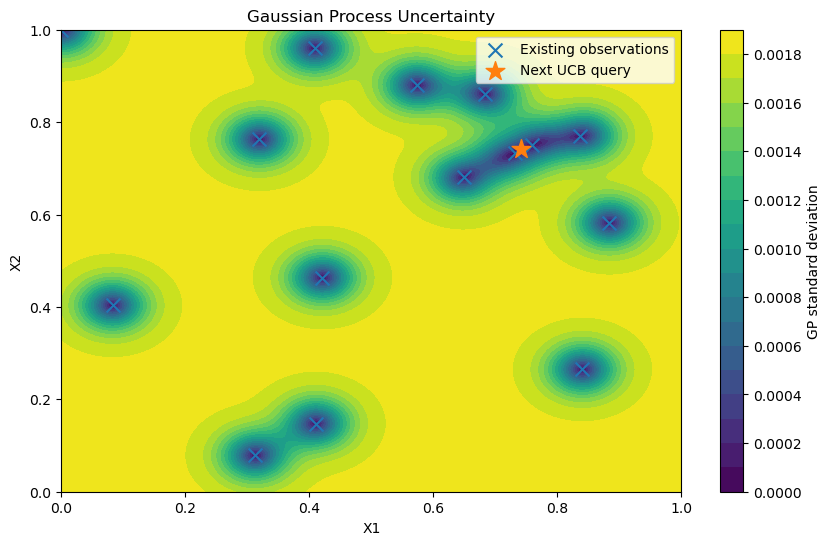

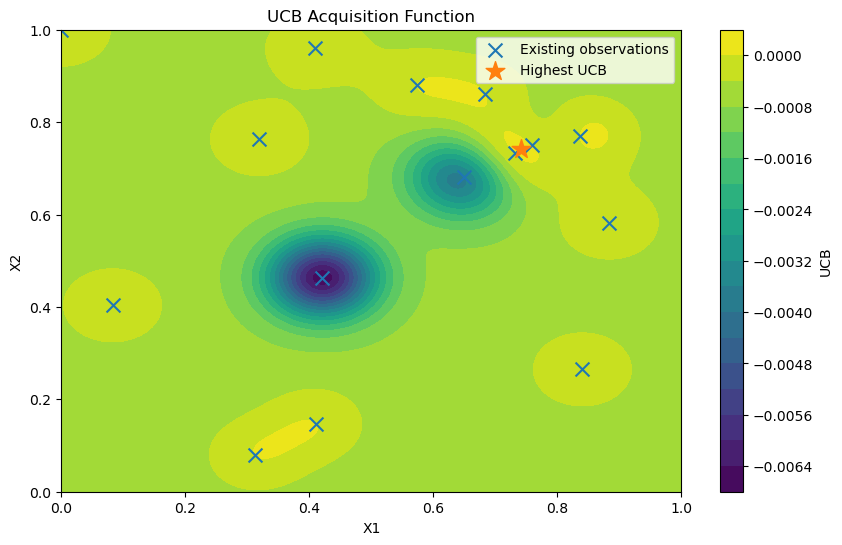

In [33]:
# Predict candidate outputs
post_mean, post_std = model.predict(
    X_grid,
    return_std=True
)
# Calculate UCB
UCB = ucb_score(post_mean, post_std, beta)
# Select the next query
best_index = np.argmax(UCB)

next_X = X_grid[best_index]

print("Next input combination suggested by UCB:")
print(next_X)

print("\nPredicted mean:")
print(post_mean[best_index])

print("\nPredicted standard deviation:")
print(post_std[best_index])

print("\nUCB:")
print(UCB[best_index])

plot_gp_diagnostics_2d(
    X1_grid, X2_grid,
    post_mean, post_std, UCB,
    X, next_X,
)

### Option 2: Select the most isolated interior candidate · selected

In [34]:
# Ensure Week 5 has been included
X = X_new
y = y_new

assert X.shape == (15, 2)
assert y.shape == (15,)

# Build nearest-neighbour search tree
tree = cKDTree(X)

# Search the interior of the input domain
values = np.linspace(0.05, 0.95, 901)

X1_grid, X2_grid = np.meshgrid(
    values,
    values
)

X_candidates = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

# Calculate nearest-observation distances
distances, _ = tree.query(X_candidates)

# Select the most isolated candidate
best_index = np.argmax(distances)

next_X = np.round(X_candidates[best_index], 6)

print("Week 6 candidate:", next_X)
print("Nearest observation distance:", distances[best_index])

Week 6 candidate: [0.05  0.683]
Nearest observation distance: 0.28101949550698546


### Evaluated query

**Input:** `(0.050000, 0.683000)`  
**Output:** `1.3029766379387713e-144`

In [35]:
X_week6 = np.array([0.05 , 0.683])
y_week6 = np.array([1.3029766379387713e-144])
X_new, y_new = add_evaluation(X, y, X_week6, y_week6)

## Week 7

In [36]:
X = X_new
y = y_new

In [37]:
# Include all observations through Week 6
X = X_new
y = y_new

assert X.shape == (16, 2)
assert y.shape == (16,)

# Fit the Matérn 3/2 GP
kernel = Matern(
    length_scale=0.1,
    length_scale_bounds=(0.015, 3.0),
    nu=1.5
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=5,
    random_state=42
)
print("Optimised kernel:", model.kernel_)

# Generate candidates across the whole domain
values = np.linspace(0, 1, 501)
x1_grid, x2_grid = np.meshgrid(values, values)

candidates = np.column_stack([
    x1_grid.ravel(),
    x2_grid.ravel()
])

# Avoid querying extremely close to previous points
distances = cKDTree(X).query(candidates)[0]
min_distance = 0.05

# Calculate GP-UCB in batches to limit memory usage
beta = 1.0
ucb = np.empty(len(candidates))

for start in range(0, len(candidates), 25000):
    end = min(start + 25000, len(candidates))

    mu, sigma = model.predict(
        candidates[start:end],
        return_std=True
    )
    ucb[start:end] = ucb_score(mu, sigma, beta)

ucb[distances < min_distance] = -np.inf

best_idx = np.argmax(ucb)
next_X = candidates[best_idx]

mu, sigma = model.predict(
    next_X.reshape(1, -1),
    return_std=True
)

print("Week 7 recommended input:", next_X)
print("Predicted mean:", mu[0])
print("Predicted std:", sigma[0])
print("UCB:", ucb[best_idx])
print("Nearest observation distance:", distances[best_idx])

Optimised kernel: Matern(length_scale=0.12, nu=1.5)
Week 7 recommended input: [0.196 0.864]
Predicted mean: -0.00016775766580027975
Predicted std: 0.0016363850453547822
UCB: 0.0014686273795545025
Nearest observation distance: 0.15949209331088482


### Evaluated query

**Input:** `(0.196000, 0.864000)`  
**Output:** `-1.3666066508501036e-170`

In [38]:
X_week7 = np.array([0.196, 0.864])
y_week7 = np.array([-1.3666066508501036e-170])
X_new, y_new = add_evaluation(X, y, X_week7, y_week7)

## Week 8

In [39]:
# All 17 observations, including Week 7
X = np.asarray(X_new, dtype=float)
y = np.asarray(y_new, dtype=float).ravel()

assert X.shape == (17, 2)
assert y.shape == (17,)

# Fit selected GP
kernel = Matern(
    length_scale=0.1,
    length_scale_bounds=(0.015, 3.0),
    nu=1.5
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=6,
    random_state=42
)
print("Optimised kernel:", model.kernel_)

# Candidate search
values = np.linspace(0, 1, 501)
x1_grid, x2_grid = np.meshgrid(values, values)

candidates = np.column_stack([
    x1_grid.ravel(),
    x2_grid.ravel()
])

# GP-UCB
beta = 1.96
min_distance = 0.05

distances = cKDTree(X).query(candidates)[0]

ucb = np.empty(len(candidates))

for start in range(0, len(candidates), 25000):
    end = min(start + 25000, len(candidates))

    mu, std = model.predict(
        candidates[start:end],
        return_std=True
    )

    ucb[start:end] = ucb_score(mu, std, beta)

ucb[distances < min_distance] = -np.inf

best_index = np.argmax(ucb)
next_X = candidates[best_index]

mu, std = model.predict(
    next_X.reshape(1, -1),
    return_std=True
)

print("Week 8 query:", next_X)
print("Predicted mean:", mu[0])
print("Predicted std:", std[0])
print("UCB:", ucb[best_index])

Optimised kernel: Matern(length_scale=0.125, nu=1.5)
Week 8 query: [0.534 0.   ]
Predicted mean: -0.00038752992540596335
Predicted std: 0.0016698853623919503
UCB: 0.0028854453848822592


### Evaluated query

**Input:** `(0.534000, 0.000000)`  
**Output:** `5.030910871402412e-134`

In [40]:
X_week8 = np.array([0.534, 0.])
y_week8 = np.array([5.030910871402412e-134])
X_new, y_new = add_evaluation(X, y, X_week8, y_week8)

## Week 9

In [41]:
# All 18 observations through Week 8
X = np.asarray(X_new, dtype=float)
y = np.asarray(y_new, dtype=float).ravel()

assert X.shape == (18, 2)
assert y.shape == (18,)
# Fit selected GP
kernel = Matern(
    length_scale=0.1,
    length_scale_bounds=(0.015, 3.0),
    nu=1.5
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=8,
    random_state=42
)

print("Optimised kernel:", model.kernel_)
# GP-UCB settings
beta = 1.96
min_distance = 0.05
tree = cKDTree(X)
# Dense candidate grid
values = np.linspace(0, 1, 501)

x1_grid, x2_grid = np.meshgrid(
    values, values
)

candidates = np.column_stack([
    x1_grid.ravel(),
    x2_grid.ravel()
])

scores = np.empty(len(candidates))

for start in range(0, len(candidates), 15000):
    end = min(start + 15000, len(candidates))

    mu, std = model.predict(
        candidates[start:end],
        return_std=True
    )

    scores[start:end] = ucb_score(mu, std, beta)

distances = tree.query(candidates)[0]
scores[distances < min_distance] = -np.inf

best_index = np.argmax(scores)
initial_x = candidates[best_index]
# Refine best acquisition candidate
def negative_ucb(point):
    point = np.asarray(point)

    mu, std = model.predict(
        point.reshape(1, -1),
        return_std=True
    )

    distance = tree.query(point)[0]

    penalty = 50 * max(
        0, min_distance - distance
    )

    return -(mu[0] + beta * std[0]) + penalty

result = minimize(
    negative_ucb,
    x0=initial_x,
    bounds=[(0, 1), (0, 1)],
    method="L-BFGS-B",
    options={"maxiter": 300, "ftol": 1e-15}
)

next_X = (
    result.x
    if result.fun < negative_ucb(initial_x)
    else initial_x
)

next_X = np.round(next_X, 6)
# Final prediction
mu, std = model.predict(
    next_X.reshape(1, -1),
    return_std=True
)

print("Week 9 query:", next_X)
print("Predicted mean:", mu[0])
print("Predicted std:", std[0])
print("UCB:", mu[0] + beta * std[0])
print(
    "Nearest observation distance:",
    tree.query(next_X)[0]
)

print("Current best observed output:", y.max())

Optimised kernel: Matern(length_scale=0.125, nu=1.5)
Week 9 query: [1.  0.4]
Predicted mean: -0.00034395445784861063
Predicted std: 0.0016150950809152573
UCB: 0.0028216319007452937
Nearest observation distance: 0.20924762303335293
Current best observed output: 7.710875114502849e-16


### Evaluated query

**Input:** `(1.000000, 0.400000)`  
**Output:** `8.50198024479626e-133`

In [42]:
X_week9 = np.array([1. , 0.4])
y_week9 = np.array([8.50198024479626e-133])
X_new, y_new = add_evaluation(X, y, X_week9, y_week9)

## Week 10

In [43]:
# All observations through Week 9
X = np.asarray(X_new, dtype=float)
y = np.asarray(y_new, dtype=float).ravel()

assert X.shape == (19, 2)
assert y.shape == (19,)

# Fit the selected GP
kernel = Matern(
    length_scale=0.1,
    length_scale_bounds=(0.015, 3.0),
    nu=1.5
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=8,
    random_state=42
)

print("Optimised kernel:", model.kernel_)

# Build candidate grid
values = np.linspace(0, 1, 1001)

x1_grid, x2_grid = np.meshgrid(
    values, values
)

candidates = np.column_stack([
    x1_grid.ravel(),
    x2_grid.ravel()
])

# Calculate nearest-observation distances
tree = cKDTree(X)

distances = tree.query(candidates)[0]

# Calculate GP-UCB
beta = 1.96
min_distance = 0.05

ucb = np.empty(len(candidates))

for start in range(0, len(candidates), 20000):
    end = min(start + 20000, len(candidates))

    mu, std = model.predict(
        candidates[start:end],
        return_std=True
    )

    ucb[start:end] = ucb_score(mu, std, beta)

# Exclude previously sampled neighbourhoods
ucb[distances < min_distance] = -np.inf

# Find the maximum GP-UCB score
best_ucb_index = np.argmax(ucb)
maximum_ucb = ucb[best_ucb_index]

# Hybrid strategy:
# Retain candidates within 2% of maximum UCB
tolerance = 0.02

eligible = (
    ucb >= maximum_ucb
           - tolerance * abs(maximum_ucb)
)

# Select the most distant eligible candidate
distance_scores = np.where(
    eligible,
    distances,
    -np.inf
)

best_index = np.argmax(distance_scores)

next_X = candidates[best_index]

# Report Week 10 recommendation
mu, std = model.predict(
    next_X.reshape(1, -1),
    return_std=True
)

print("\nWeek 10 query:", next_X)
print("Predicted mean:", mu[0])
print("Predicted std:", std[0])
print("GP-UCB:", mu[0] + beta * std[0])
print(
    "Nearest observation distance:",
    distances[best_index]
)
print(
    "Maximum GP-UCB candidate:",
    candidates[best_ucb_index]
)
print("Current best output:", y.max())

Optimised kernel: Matern(length_scale=0.126, nu=1.5)

Week 10 query: [0. 0.]
Predicted mean: -0.0005005335894563354
Predicted std: 0.001640927194421791
GP-UCB: 0.002715683711610375
Nearest observation distance: 0.3224485002380642
Maximum GP-UCB candidate: [1.    0.119]
Current best output: 7.710875114502849e-16


### Evaluated query

**Input:** `(0.000000, 0.000000)`  
**Output:** `2.308810742126141e-248`

In [44]:
X_week10 = np.array([0., 0.])
y_week10 = np.array([2.308810742126141e-248])
X_new, y_new = add_evaluation(X, y, X_week10, y_week10)

## Week 11

In [45]:
# All observations, including Week 10
X = np.asarray(X_new, dtype=float)
y = np.asarray(y_new, dtype=float).ravel()

assert X.shape == (20, 2)
assert y.shape == (20,)

# Identify the best observation
best_index = np.argmax(y)
best_X = X[best_index]
best_y = y[best_index]

# Controlled extrapolation from Week 4
step_fraction = 0.625
direction = best_X - X_week4

next_X = np.clip(
    best_X + step_fraction * direction,
    0, 1
)

next_X = np.round(next_X, 6)

# Distance checks
tree = cKDTree(X)
nearest_distance = tree.query(next_X)[0]

# Refit the existing GP with all 20 observations
kernel = Matern(
    length_scale=0.1,
    length_scale_bounds=(0.015, 3.0),
    nu=1.5
)

model = fit_gp_model(
    X, y,
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=8,
    random_state=42
)

mu, std = model.predict(
    next_X.reshape(1, -1),
    return_std=True
)

beta = 1.96
ucb = mu[0] + beta * std[0]

print("Optimised kernel:", model.kernel_)
print("Best observed input:", best_X)
print("Best observed output:", best_y)
print()
print("Week 11 proposed input:", next_X)
print("Predicted mean:", mu[0])
print("Predicted std:", std[0])
print("GP-UCB:", ucb)
print("Nearest observation distance:", nearest_distance)

Optimised kernel: Matern(length_scale=0.123, nu=1.5)
Best observed input: [0.73102363 0.73299988]
Best observed output: 7.710875114502849e-16

Week 11 proposed input: [0.713663 0.72275 ]
Predicted mean: -0.0004942014252417874
Predicted std: 0.00027096590530015387
GP-UCB: 3.689174914651419e-05
Nearest observation distance: 0.020160641699368247


### Evaluated query

**Input:** `(0.713663, 0.722750)`  
**Output:** `9.814086725879846e-12`

In [46]:
X_week11 = np.array([0.713663, 0.72275])
y_week11 = np.array([9.814086725879846e-12])
X_new, y_new = add_evaluation(X, y, X_week11, y_week11)

## Week 12

In [47]:
# Observations through Week 11
X = np.asarray(X_new, dtype=float)
y = np.asarray(y_new, dtype=float).ravel()

assert X.shape == (21, 2)
assert y.shape == (21,)

best_idx = np.argmax(y)

print("Current best input:", X[best_idx])
print("Current best output:", y[best_idx])
# Identify the earlier reference points
initial_best_idx = np.argmax(y[:10])

initial_best_X = X[initial_best_idx]

week4_X = np.asarray(
    X_week4, dtype=float
).ravel()

# Direction from Week 4 to initial best
direction = initial_best_X - week4_X
# Controlled directional extrapolation
step_factor = 2.5

next_X = np.clip(
    week4_X + step_factor * direction,
    0,
    1
)

next_X = np.round(next_X, 6)
# Distance checks
tree = cKDTree(X)

nearest_distance = tree.query(next_X)[0]

negative_X = X[y < 0]

nearest_negative_distance = np.min(
    np.linalg.norm(
        negative_X - next_X,
        axis=1
    )
)
# Review recent improvements
previous_best = np.max(y[:20])
week11_output = y[-1]

print("\nWeek 11 improvement factor:")
print(week11_output / previous_best)

print("\nWeek 12 proposed input:")
print(" ".join(f"{v:.6f}" for v in next_X))

print(
    "Nearest observation distance:",
    nearest_distance
)

print(
    "Nearest negative observation distance:",
    nearest_negative_distance
)

print(
    "Distance from Week 11:",
    np.linalg.norm(next_X - X[-1])
)

Current best input: [0.713663 0.72275 ]
Current best output: 9.814086725879846e-12

Week 11 improvement factor:
12727.591330614618

Week 12 proposed input:
0.689359 0.708400
Nearest observation distance: 0.028224225693542045
Nearest negative observation distance: 0.04756425427766469
Distance from Week 11: 0.028224225693542045


### Evaluated query

**Input:** `(0.689359, 0.708400)`  
**Output:** `1.5093304096604603e-07`

In [48]:
X_week12 = np.array([0.689359, 0.7084])
y_week12 = np.array([1.5093304096604603e-07])
X_new, y_new = add_evaluation(X, y, X_week12, y_week12)

## Week 13

In [49]:
# Load observations through Week 12
X_all = np.asarray(X_new, dtype=float)
y_all = np.asarray(y_new, dtype=float).ravel()

assert X_all.shape == (22, 2)
assert y_all.shape == (22,)

best_idx = np.argmax(y_all)

print("Current best input:", X_all[best_idx])
print("Current best output:", y_all[best_idx])
# Define the relevant observations
# Initial observation 5: negative output
negative_X = X_all[4]

# Week 12: best positive output
week12_X = X_all[-1]

# Direction from negative point to Week 12
direction = week12_X - negative_X

unit_direction = direction / np.linalg.norm(direction)

# Relevant observations:
# Initial negative, Week 12, Week 11,
# Initial positive observation 3, Week 4
indices = [4, 21, 20, 2, 13]

local_X = X_all[indices]
local_y = y_all[indices]
# Fit quadratic to log absolute outputs
t = (local_X - negative_X) @ unit_direction

log_magnitude = np.log(np.abs(local_y))

coefficients = np.polyfit(
    t,
    log_magnitude,
    deg=2
)

def predicted_magnitude(t_value):
    return np.exp(
        np.polyval(coefficients, t_value)
    )

print("\nLog-magnitude coefficients:")
print(coefficients)
# Evaluate possible final queries
for t_value in [0.020, 0.025, 0.030, 0.035, 0.040]:

    candidate = (
        negative_X
        + t_value * unit_direction
    )

    magnitude = predicted_magnitude(t_value)

    print(
        f"t={t_value:.3f}",
        "Coordinates:",
        np.round(candidate, 6),
        "Estimated |output|:",
        f"{magnitude:.6e}"
    )
# Select the final submission
t_selected = 0.030

next_X = (
    negative_X
    + t_selected * unit_direction
)

next_X = np.round(next_X, 6)

print("\nFinal Week 13 submission:")
print(" ".join(f"{v:.6f}" for v in next_X))

print(
    "Estimated output magnitude:",
    predicted_magnitude(t_selected)
)

print(
    "Distance from Week 12:",
    np.linalg.norm(next_X - week12_X)
)

print(
    "Distance from negative observation:",
    np.linalg.norm(next_X - negative_X)
)

print("\nImportant: Output sign is unknown.")

Current best input: [0.689359 0.7084  ]
Current best output: 1.5093304096604603e-07

Log-magnitude coefficients:
[-1986.70962302  -112.72976291    -5.66323171]
t=0.020 Coordinates: [0.666616 0.692826] Estimated |output|: 1.645147e-04
t=0.025 Coordinates: [0.670741 0.695651] Estimated |output|: 5.987992e-05
t=0.030 Coordinates: [0.674867 0.698476] Estimated |output|: 1.973408e-05
t=0.035 Coordinates: [0.678992 0.701301] Estimated |output|: 5.888597e-06
t=0.040 Coordinates: [0.683118 0.704126] Estimated |output|: 1.590984e-06

Final Week 13 submission:
0.674867 0.698476
Estimated output magnitude: 1.9734084049595694e-05
Distance from Week 12: 0.01756427738337113
Distance from negative observation: 0.029999976898137312

Important: Output sign is unknown.


### Week 13 evaluated result

**Input:** `(0.674867, 0.698476)`  
**Output:** `6.7561592247023674e-06`

The query-selection calculations above use results available through Week 12. The full record is in [`weekly_submissions.csv`](../submissions/weekly_submissions.csv).